**Yuxuan Lin**

# Assignment 10: Inference for Regression

**Relevant reading for this problem set**:
<a href="https://moderndive.com/10-inference-for-regression.html"
target="_blank">ModernDive Chapter 10: Inference for Regression</a>.

## Background

For this problem set you will apply statistical inference to a linear
modeling and explore methods to check the required conditions. To start
we will build a model using data from the `palmerpenguins` package. The
`penguins` data contains size measurements for three penguin species
observed on three islands in the Palmer Archipelago, Antarctica.

First we will start with our typical exploratory data analysis and then
build our linear model. From there we will use our new skills to make
inferences about our regression model and check the necessary
conditions.

### Load packages

We will read the data in from the`palmerpenguins` package, explore the
data using the `dplyr` package and visualize it using the `ggplot2`
package. The `moderndive` package includes some nice functions to show
regression model outputs and finally use the `infer` package for “tidy”
and transparent statistical inference.

In [1]:
library('moderndive')
library('infer')
library('palmerpenguins')
library('tidymodels')

options(repr.plot.width = 7, repr.plot.height = 5)


Attaching package: ‘palmerpenguins’




The following objects are masked from ‘package:datasets’:

    penguins, penguins_raw




── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──



✔ broom        1.0.13     ✔ rsample      1.3.2 
✔ dials        1.4.4      ✔ tailor       0.1.0 
✔ dplyr        1.2.1      ✔ tidyr        1.3.2 
✔ ggplot2      4.0.3      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.6.0      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
✔ recipes      1.3.3      



── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()



### The data

In [2]:
pen = palmerpenguins::penguins |> 
  filter(!is.na(flipper_length_mm))

glimpse(pen)
head(pen)

Rows: 342
Columns: 8
$ species           <fct> Adelie, Adelie, Adelie, Adelie, Adelie, Adelie, Adel…
$ island            <fct> Torgersen, Torgersen, Torgersen, Torgersen, Torgerse…
$ bill_length_mm    <dbl> 39.1, 39.5, 40.3, 36.7, 39.3, 38.9, 39.2, 34.1, 42.0…
$ bill_depth_mm     <dbl> 18.7, 17.4, 18.0, 19.3, 20.6, 17.8, 19.6, 18.1, 20.2…
$ flipper_length_mm <int> 181, 186, 195, 193, 190, 181, 195, 193, 190, 186, 18…
$ body_mass_g       <int> 3750, 3800, 3250, 3450, 3650, 3625, 4675, 3475, 4250…
$ sex               <fct> male, female, female, female, male, female, male, NA…
$ year              <int> 2007, 2007, 2007, 2007, 2007, 2007, 2007, 2007, 2007…


species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
Adelie,Torgersen,39.1,18.7,181,3750,male,2007
Adelie,Torgersen,39.5,17.4,186,3800,female,2007
Adelie,Torgersen,40.3,18.0,195,3250,female,2007
Adelie,Torgersen,36.7,19.3,193,3450,female,2007
Adelie,Torgersen,39.3,20.6,190,3650,male,2007
Adelie,Torgersen,38.9,17.8,181,3625,female,2007


Take a moment to look at the data using `glimpse` and `head`. The dataset contains 8
variables. You can read more about the variables by placing your cursor in `penguins` and 
looking at the `Contextual Help` tool.

For our lab we will focus on four variables, the explanatory variables
include:

-   `flipper_length_mm` - an integer denoting flipper length
    (millimeters)
-   `bill_length_mm` - a number denoting bill length (millimeters)
-   `species`- denotes penguin species (Adélie, Chinstrap and Gentoo)

The outcome variable `body_mass_g` is an integer denoting body mass
(grams).

**Data note:** Loading tidymodels also loads another dataset called penguins. I use `palmerpenguins::penguins` explicitly so this is the eight-variable dataset described in the question. After removing the two rows with missing flipper length, 342 penguins remain, with no missing values in the variables used in either model.

### Visualization

We will start by investigating the relationship between
‘flipper_length_mm’ and ‘body_mass_g’.

`geom_smooth()` using formula = 'y ~ x'


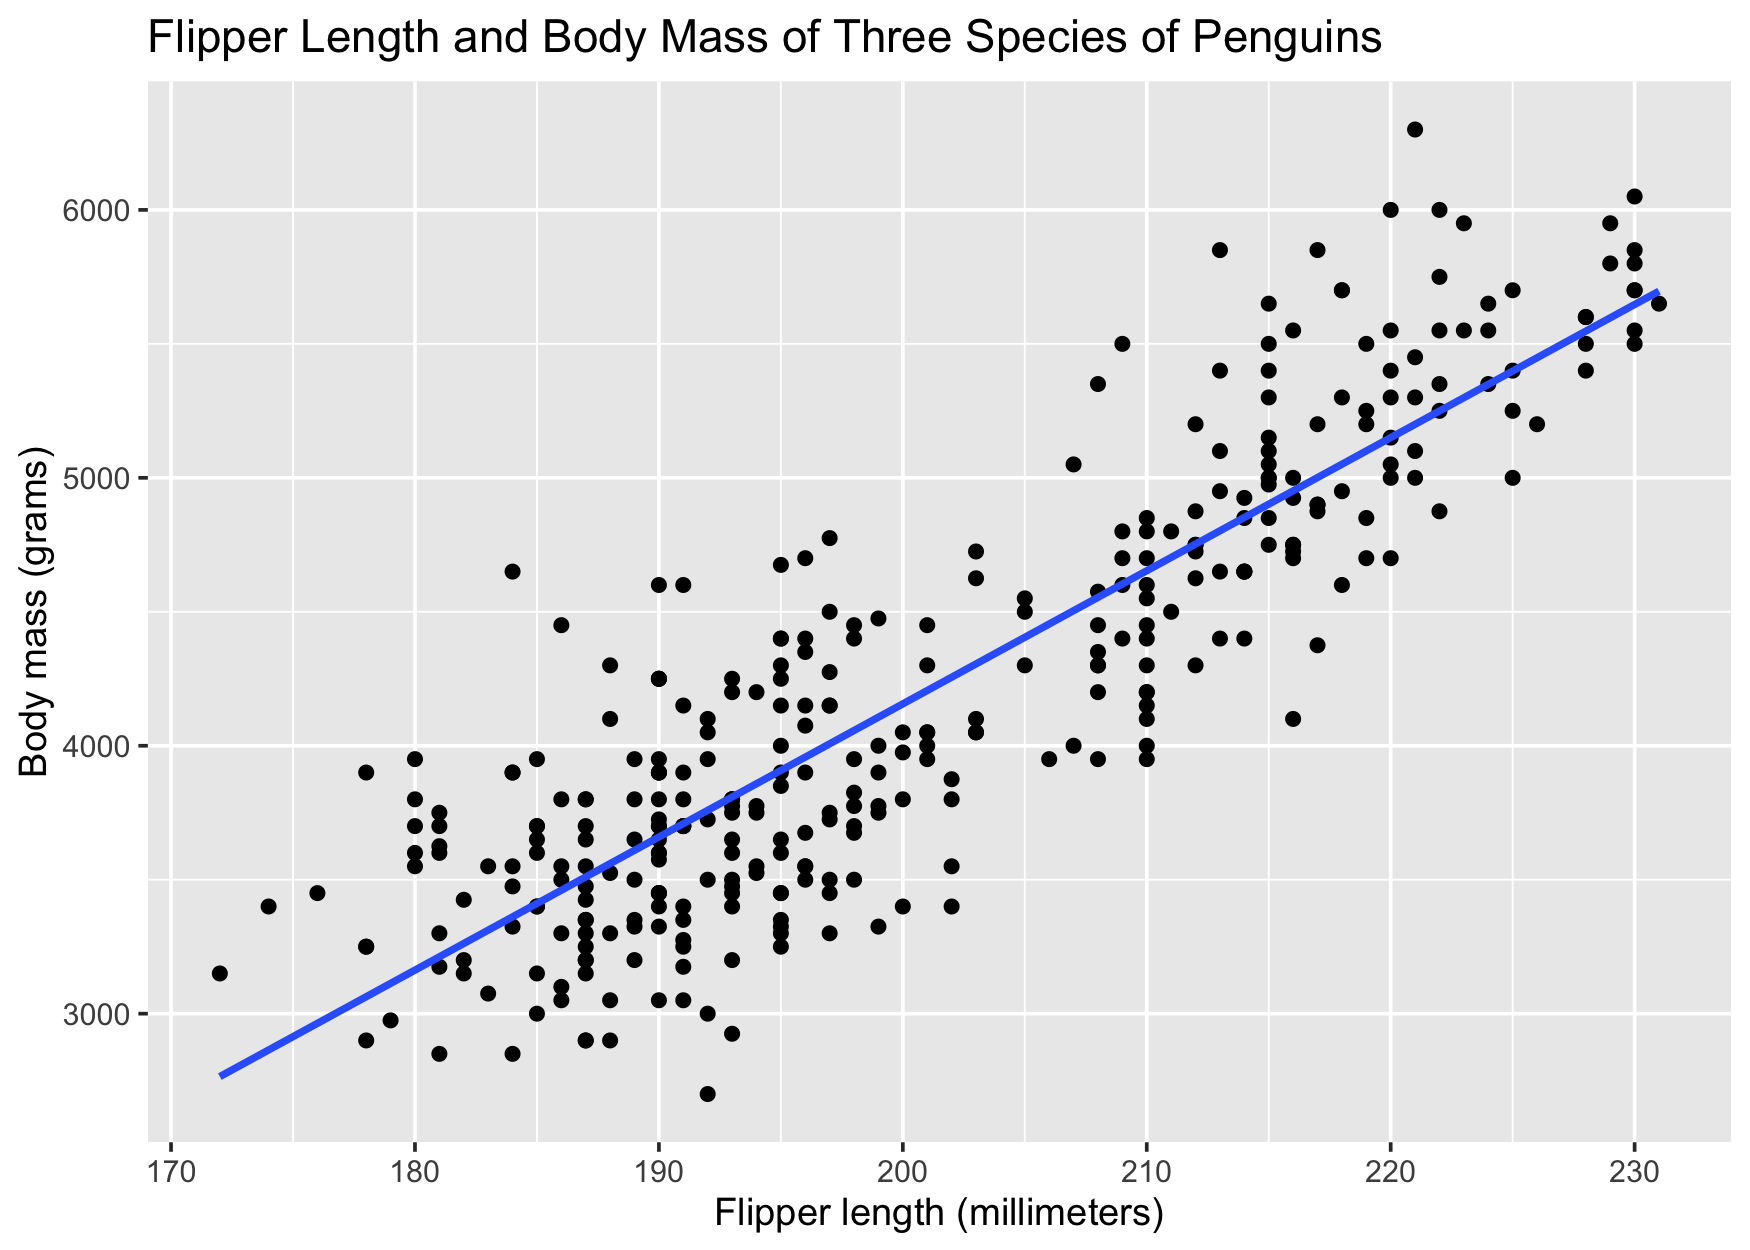

In [3]:
ggplot(data = pen, aes(y = body_mass_g, x = flipper_length_mm)) + 
  geom_point() + 
  geom_smooth(method = "lm", se = FALSE) +
  labs(x = "Flipper length (millimeters)", 
       y = "Body mass (grams)", 
       title = "Flipper Length and Body Mass of Three Species of Penguins") 

## Question 1

Does the relationship appear to be positive or negative? Does it look to
be reasonably linear?

**Answer:**

The relationship is positive: penguins with longer flippers tend to be heavier. The overall pattern looks reasonably linear, although there is still a lot of variation around the line.

## Create a linear regression model

Here we use the [standard error](https://moderndive.com/10-inference-for-regression.html#regression-se) to calculate a confidence interval. Later we will use the bootstrap resampling technique
that does not rely on distrubutional assumptions.

**My note:** The row bootstrap below does not require normally distributed residuals, but it still assumes independent observations and does not fix problems with how the sample was collected.

In [4]:
mod = linear_reg() |> set_engine('lm')

pen_model = mod |> fit(body_mass_g ~ flipper_length_mm, data = pen)

tidy(pen_model) |> mutate(lower_ci = estimate - 1.96 * std.error, upper_ci = estimate + 1.96 * std.error)

term,estimate,std.error,statistic,p.value,lower_ci,upper_ci
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),-5780.83136,305.814504,-18.90306,5.587301e-55,-6380.22779,-5181.43493
flipper_length_mm,49.68557,1.518404,32.72223,4.370681e-107,46.70949,52.66164


## Question 2

Using our shorthand interpretation for confidence intervals and the
regression table, write a sentence interpreting the 95% confidence
interval for $\beta_1$?

**Answer:**

We are 95% confident that the population slope is between 46.71 and 52.66 grams per millimeter. In this model, an additional 1 mm of flipper length is associated with an increase of about 46.71 to 52.66 grams in mean body mass for the population represented by these data. This interval is for the slope, not for the body mass of one penguin.

In [5]:
slope_table = tidy(pen_model) |>
  filter(term == "flipper_length_mm") |>
  mutate(lower_ci = estimate - 1.96 * std.error,
         upper_ci = estimate + 1.96 * std.error)

slope_table

term,estimate,std.error,statistic,p.value,lower_ci,upper_ci
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
flipper_length_mm,49.68557,1.518404,32.72223,4.370681e-107,46.70949,52.66164


## Question 3

Recall that the test statistic and $p$-value correspond to the
hypothesis test:

$$\begin{aligned} H_0:&\beta_{1} = 0 \\\ \mbox{vs }H_A:& \beta_{1} \neq 0 \end{aligned}$$

Write up the results & conclusions for this hypothesis test.

**Answer:**

The estimated slope is 49.69 grams per millimeter, with t = 32.72 and p < 0.001. Using a significance level of 0.05, I reject the null hypothesis that the slope is zero. Under the regression assumptions, there is strong evidence of a positive linear association between flipper length and body mass. This does not show that longer flippers cause greater body mass.

In [6]:
tidy(pen_model) |>
  filter(term == "flipper_length_mm") |>
  select(term, estimate, statistic, p.value)

term,estimate,statistic,p.value
<chr>,<dbl>,<dbl>,<dbl>
flipper_length_mm,49.68557,32.72223,4.370681e-107


## Question 4

You may remember that this hypothesis test is only valid if certain
“conditions for inference for regression” are met. Let’s take a closer
look those conditions.

1.  Linearity of relationship between variables
2.  Independence of the residuals
3.  Normality of the residuals
4.  Equality of variance of the residuals

## Linearity of relationship between variables

**4a) ** This was analyzed in question 1. Did you say that the
relationship between `flipper_length_mm` and `body_mass_g` appears to be
linear?

**Answer:**

Yes, as a first approximation. The scatterplot shows a strong upward trend without a large overall curve. However, the residual plot below has some grouping, so the single straight line does not capture every feature of the data.

In [7]:
pen |>
  summarize(correlation = cor(flipper_length_mm, body_mass_g))

correlation
<dbl>
0.8712018


## Independence of the residuals

The observations in our data must be independent of one another. In this
data, we can not be sure this is case, for example, some of the penguins
included may be related (siblings, parents). We are not given enough
information to verify this condition has been met.

## Normality of the residuals

The third condition is that the residuals should follow a Normal
distribution centered 0. To check for normality, create a histogram.

The code to get the residuals is given.

In [8]:
regression_points = augment(pen_model, new_data = pen)

regression_points |> head()

.pred,.resid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>,<int>
3212.256,537.743839,Adelie,Torgersen,39.1,18.7,181,3750,male,2007
3460.684,339.316007,Adelie,Torgersen,39.5,17.4,186,3800,female,2007
3907.854,-657.854091,Adelie,Torgersen,40.3,18.0,195,3250,female,2007
3808.483,-358.482958,Adelie,Torgersen,36.7,19.3,193,3450,female,2007
3659.426,-9.426259,Adelie,Torgersen,39.3,20.6,190,3650,male,2007
3212.256,412.743839,Adelie,Torgersen,38.9,17.8,181,3625,female,2007


**4b)**

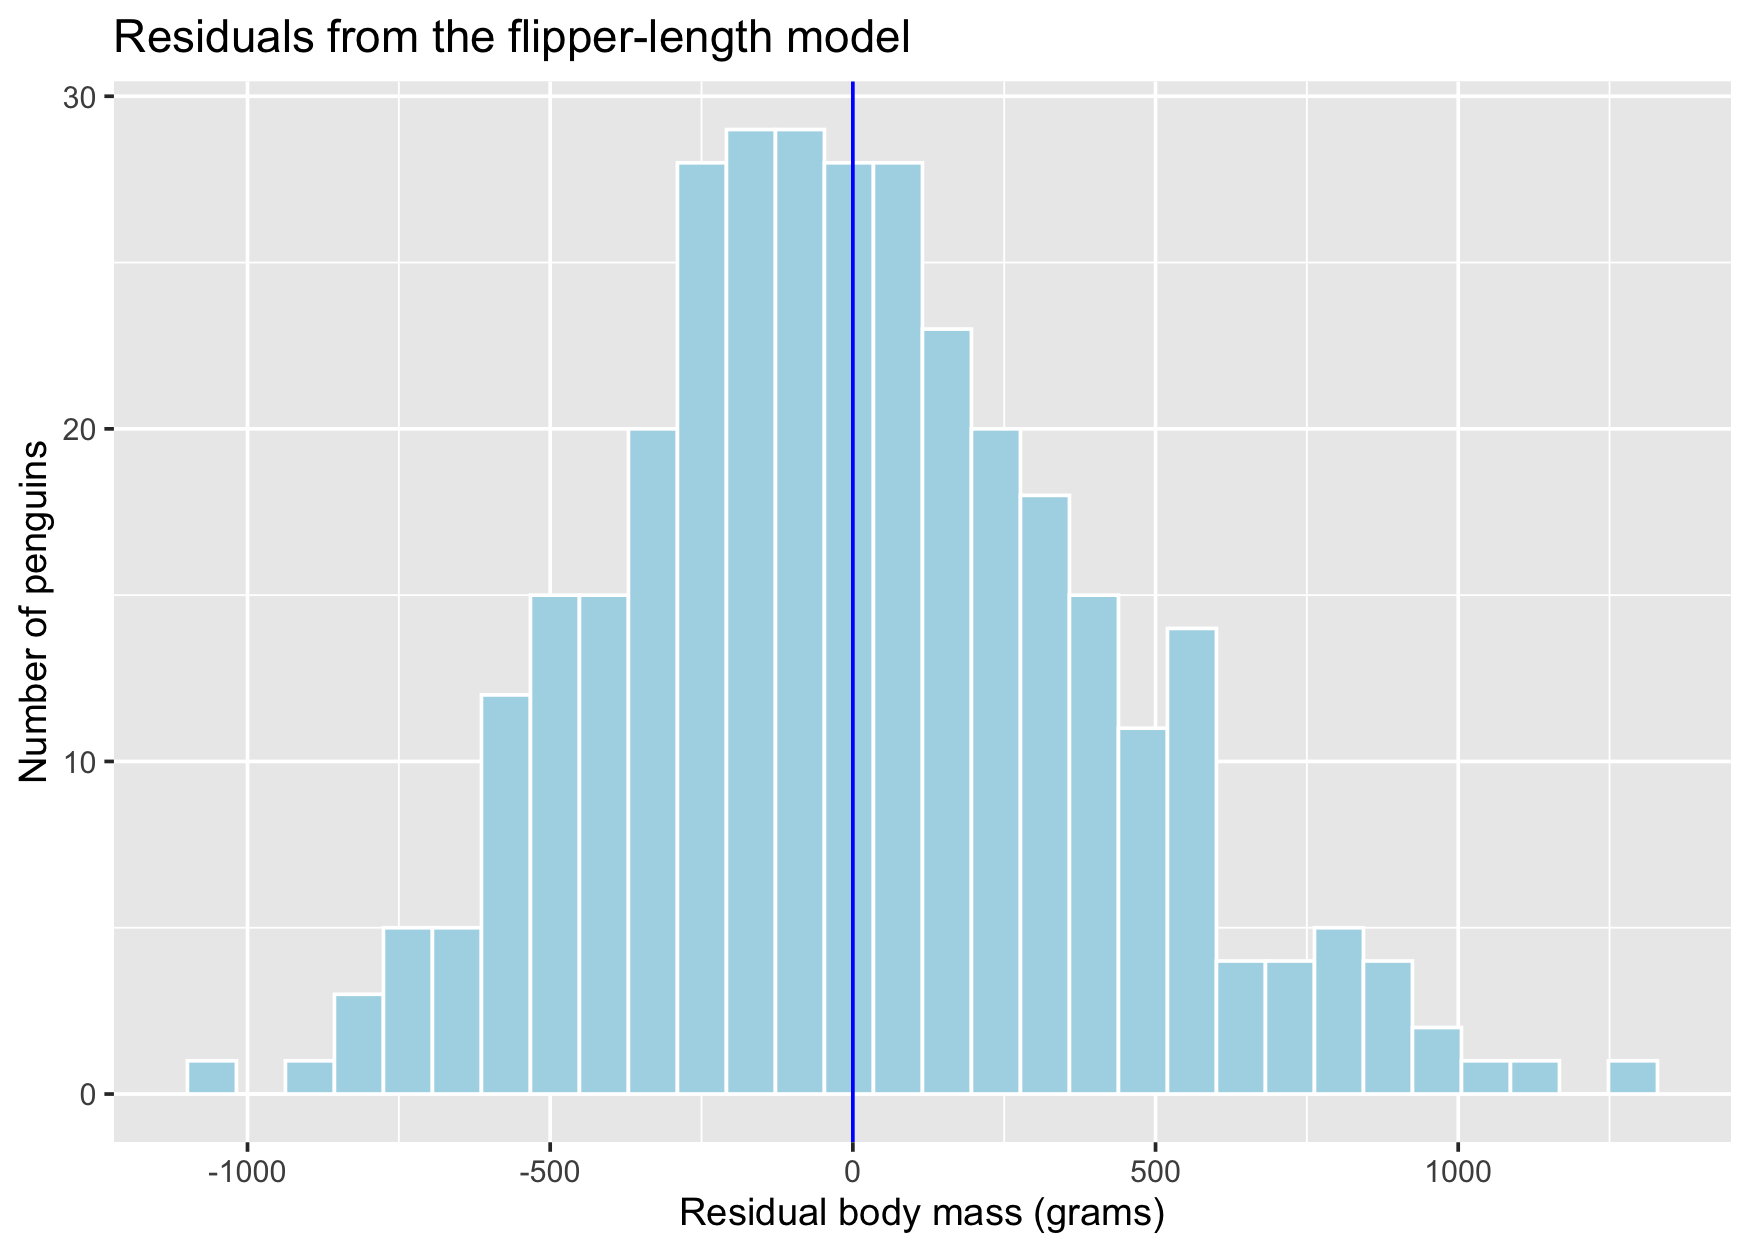

In [9]:
ggplot(regression_points, aes(x = .resid)) +
  geom_histogram(bins = 30, fill = "lightblue", color = "white") +
  geom_vline(xintercept = 0, color = "blue") +
  labs(title = "Residuals from the flipper-length model",
       x = "Residual body mass (grams)", y = "Number of penguins")

**4c)** Does this model meet the normality of residuals condition?

**Answer:**

I would say it is approximately met. The histogram is roughly bell-shaped and centered near zero, with a slightly longer right tail. The Q-Q plot is fairly straight in the middle but departs from the line in the tails. It is not a perfect normal distribution.

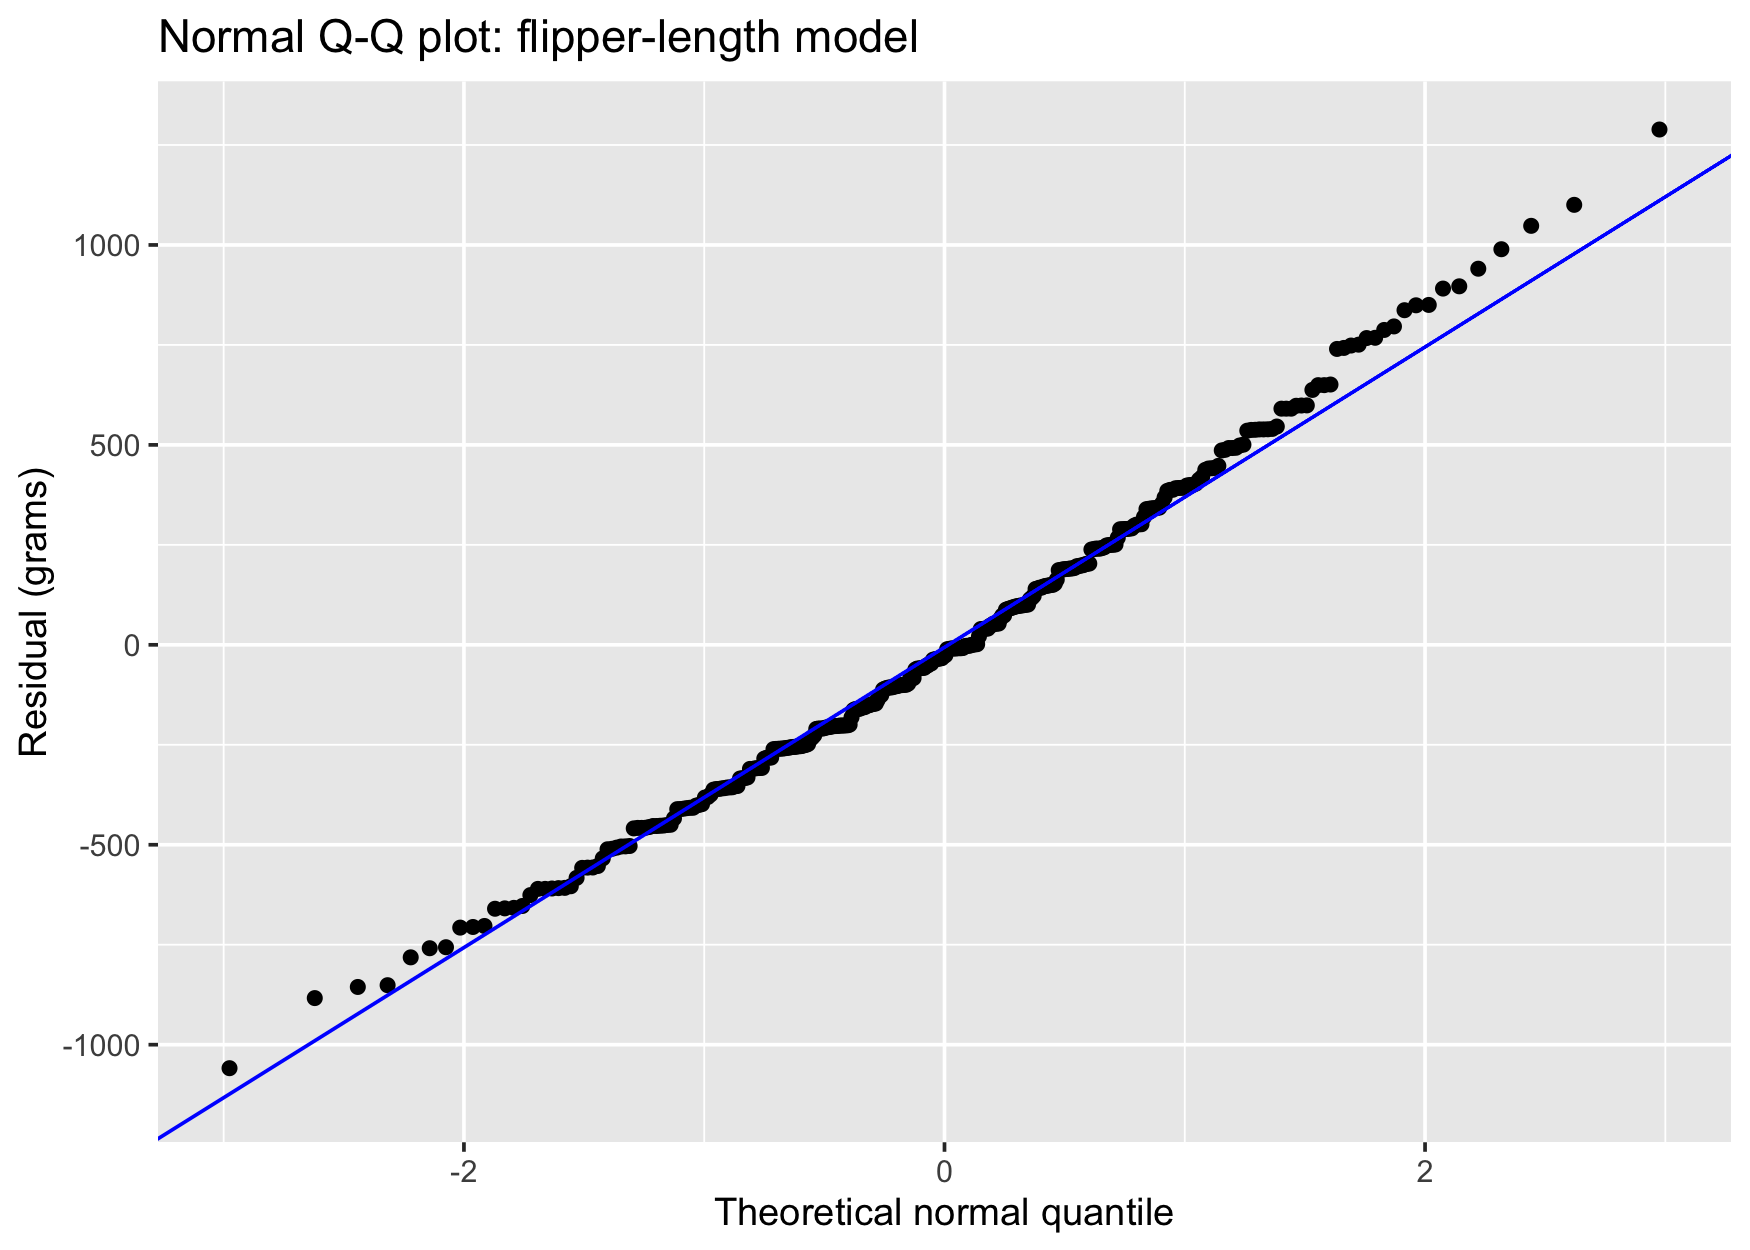

In [10]:
ggplot(regression_points, aes(sample = .resid)) +
  stat_qq() +
  stat_qq_line(color = "blue") +
  labs(title = "Normal Q-Q plot: flipper-length model",
       x = "Theoretical normal quantile", y = "Residual (grams)")

## Equality of variance of the residuals

The final condition says that the residual should exhibit equal variace
across all of the values of the explanatory variable.

To check this condition we can create a scatterplot that has our
explanatory variable, `flipper_length_mm`, on the x-axis and our
residuals on the y-axis. Does this model meet the Normality of Residuals
condition?

**My note:** This section checks equal variance; the final reference to normality appears to be a wording error.

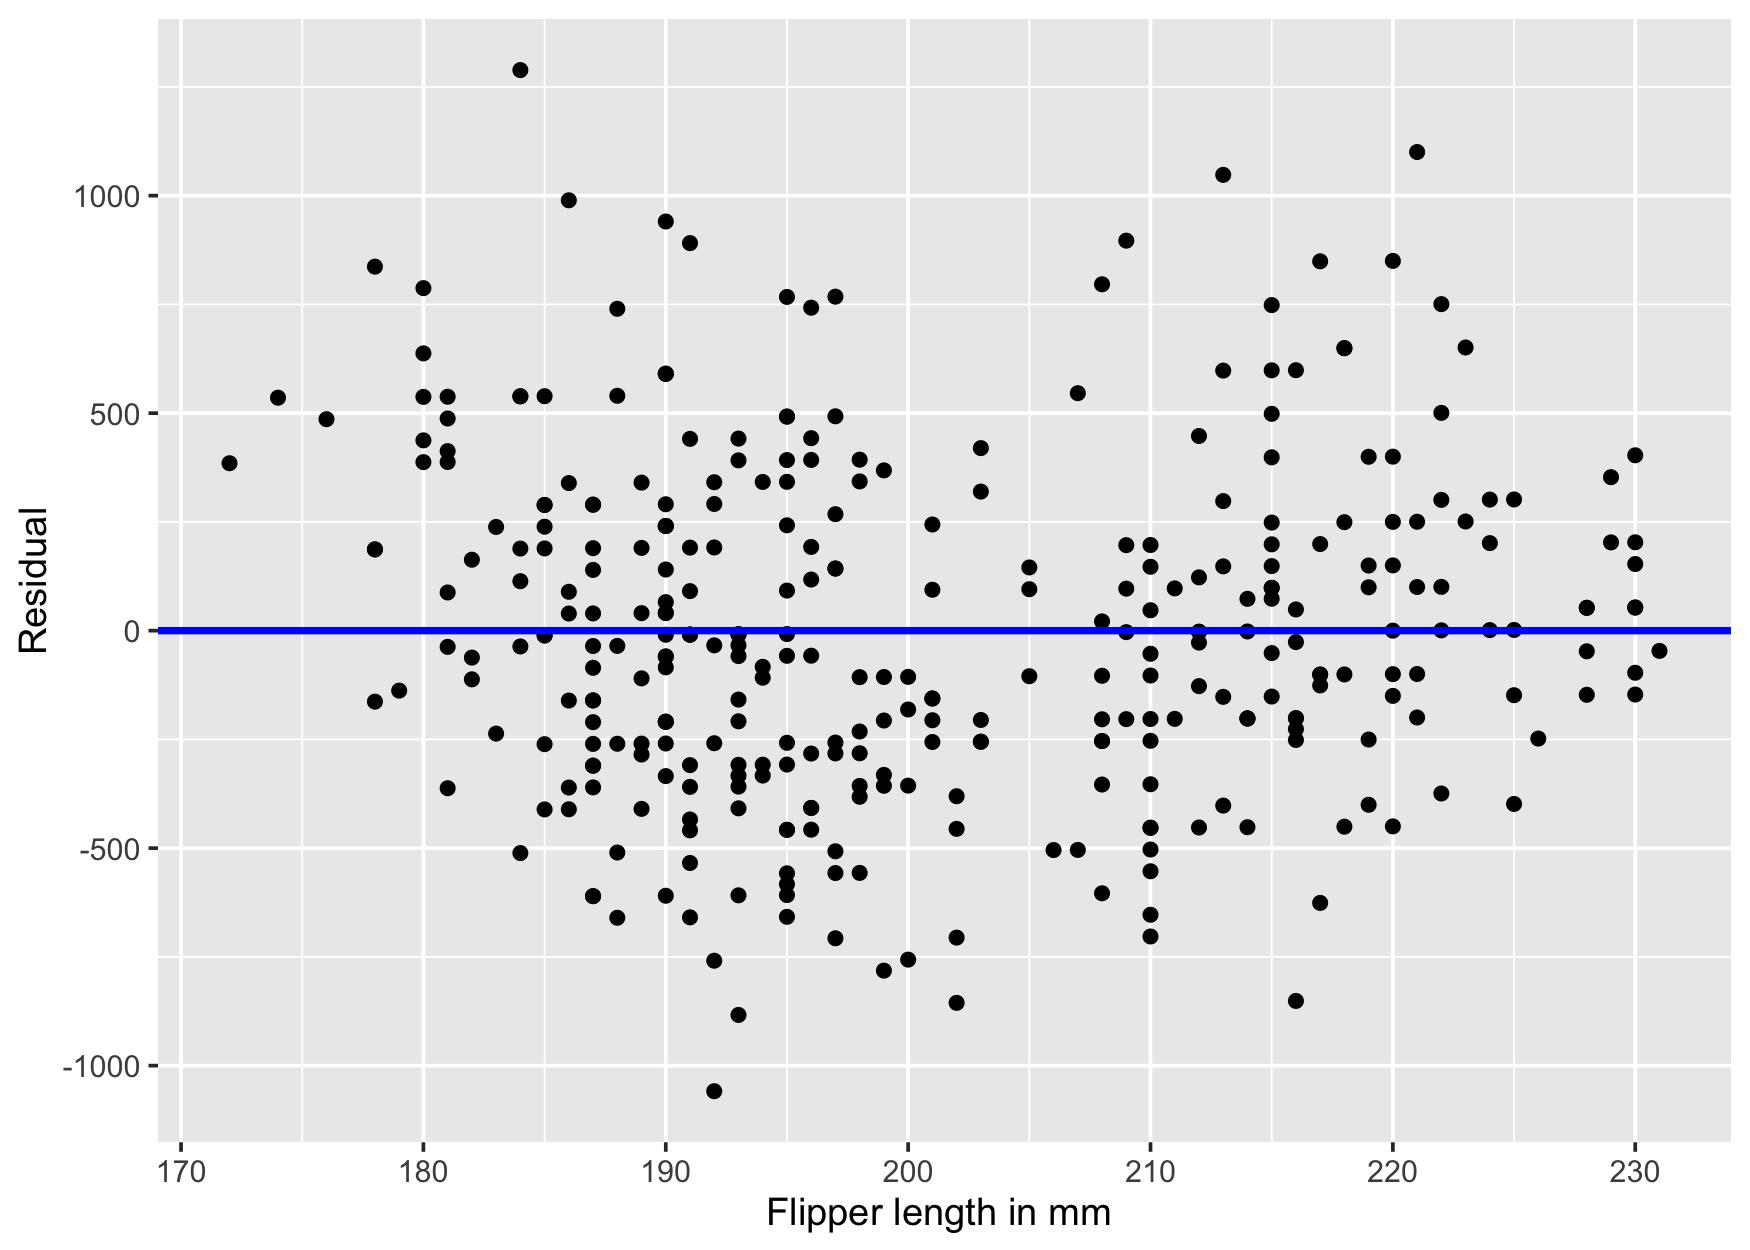

In [11]:
ggplot(regression_points, aes(x = flipper_length_mm, y = .resid)) +
  geom_point() +
  labs(x = "Flipper length in mm ", y = "Residual") +
  geom_hline(yintercept = 0, col = "blue", linewidth = 1)

**4d.** Does this model meet the equality of variance condition?

**Answer:**

The variance looks roughly constant. I do not see a clear funnel that keeps widening or narrowing as flipper length increases. The residual standard deviations in four flipper-length groups are about 348 to 389 grams, which are fairly similar. I would treat equal variance as a reasonable approximation, not as proven.

In [12]:
regression_points |>
  mutate(flipper_group = cut(flipper_length_mm, breaks = 4)) |>
  group_by(flipper_group) |>
  summarize(n = n(), residual_sd = sd(.resid))

flipper_group,n,residual_sd
<fct>,<int>,<dbl>
"(172,187]",48,383.9355
"(187,202]",152,385.7899
"(202,216]",83,388.8231
"(216,231]",59,348.0364


## Question 5

Now let’s circle back and take a second look at the confidence
intervals. Using this bootstrap distribution, we’ll construct the 95%
confidence interval using the percentile method and (if appropriate) the
standard error method as well. We can compare our results to the results
from R (which uses mathematical formula to construct confidence
intervals.)

### Step 1: Calculate the bootstrap statistic and Visualize the bootstrap distribution

The bootstrap slope distribution looks roughly symmetric and bell-shaped, so I also calculate the standard error interval using the observed slope plus or minus 1.96 times the bootstrap standard error.

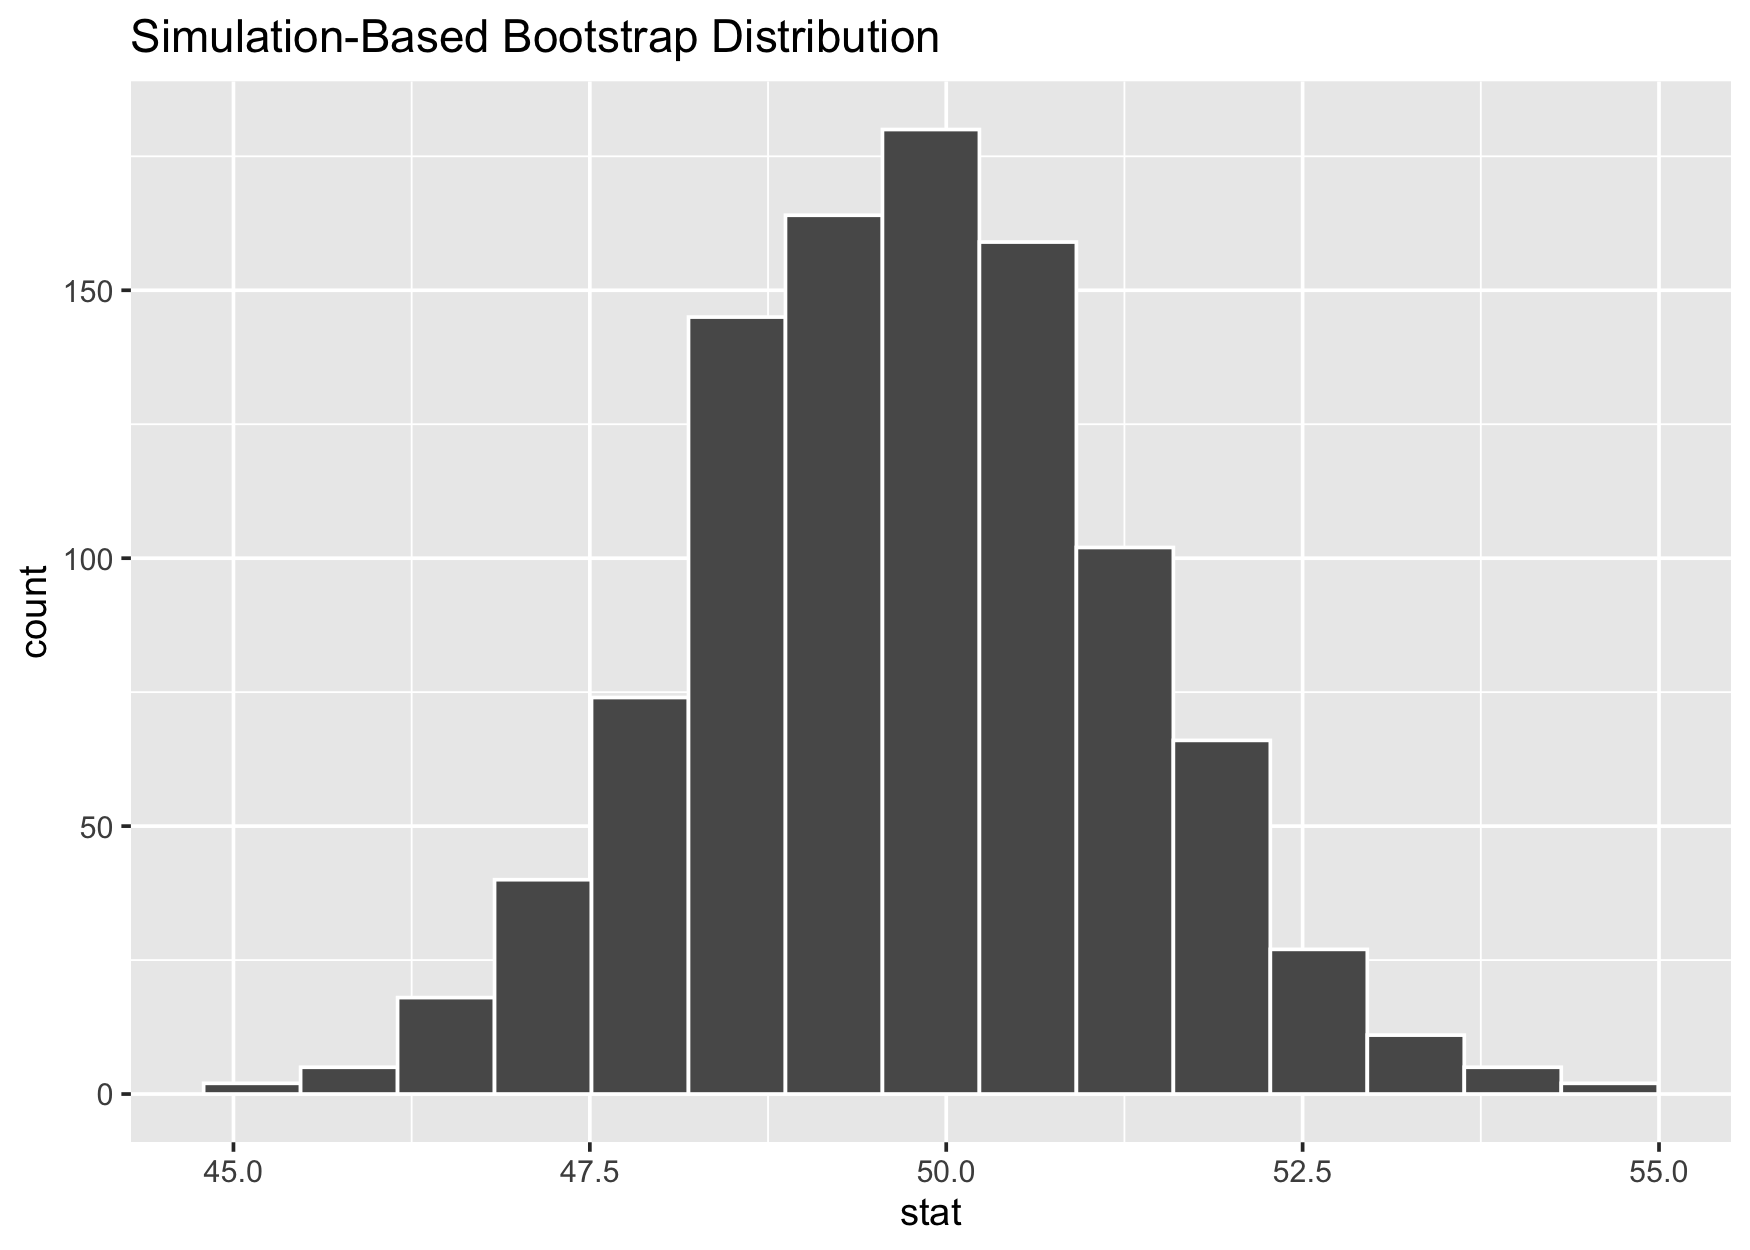

In [13]:
set.seed(42)

bootstrap_distn_slope = pen |> 
  specify(formula = body_mass_g ~ flipper_length_mm) |>
  generate(reps = 1000, type = "bootstrap") |>
  calculate(stat = "slope")

visualize(bootstrap_distn_slope)

### Step 2: Calculate CI from the a bootstap resample using the percentile method.

Find a 95% CI using percentile method:

In [14]:
slope_percentile_ci = bootstrap_distn_slope |>
  summarize(lower_ci = quantile(stat, 0.025),
            upper_ci = quantile(stat, 0.975))

slope_percentile_ci

observed_slope = slope_table$estimate
slope_se_ci = bootstrap_distn_slope |>
  summarize(se = sd(stat),
            lower_ci = observed_slope - 1.96 * se,
            upper_ci = observed_slope + 1.96 * se)

slope_se_ci

lower_ci,upper_ci
<dbl>,<dbl>
46.8523,52.65523


se,lower_ci,upper_ci
<dbl>,<dbl>,<dbl>
1.493694,46.75793,52.61321


## Question 6

Write down the two 95% confidence intervals for the $\beta_{1}$. a, b,
c, and d with the appropriate values you’ve computed.

When you are done, make sure all the `|` in the table still line up so
your results print out in a table!

| CI construction method                                                      | lower value   | upper value   |
|-----------------------------------------------------------------------------|---------------|---------------|
| Using bootstrap: percentile rule                                            | 46.852        | 52.655        |
| Using mathematical formula (see [above](#Create-a-linear-regression-model)) | 46.709        | 52.662        |

In your opinion, would you say these three confidence intervals are
similar?

**Answers:**

The two intervals in the table are very similar. Both are close to 46.7 to 52.7 grams per millimeter and are above zero.

The optional bootstrap standard error interval is 46.758 to 52.613. It is also very similar. The question mentions three intervals but lists two methods in its table, so I kept the two requested rows and reported this third interval separately.

In [15]:
bind_rows(
  "Bootstrap percentile" = slope_percentile_ci,
  "Mathematical formula" = slope_table |> select(lower_ci, upper_ci),
  "Bootstrap standard error" = slope_se_ci |> select(lower_ci, upper_ci),
  .id = "method"
)

method,lower_ci,upper_ci
<chr>,<dbl>,<dbl>
Bootstrap percentile,46.85230,52.65523
Mathematical formula,46.70949,52.66164
Bootstrap standard error,46.75793,52.61321


## Part 2

For the next part you will check the conditions for regression inference
for a new model. This model will have `bill_length_mm` and `species` as
explanatory variables, and we’ll use the parallel slopes model

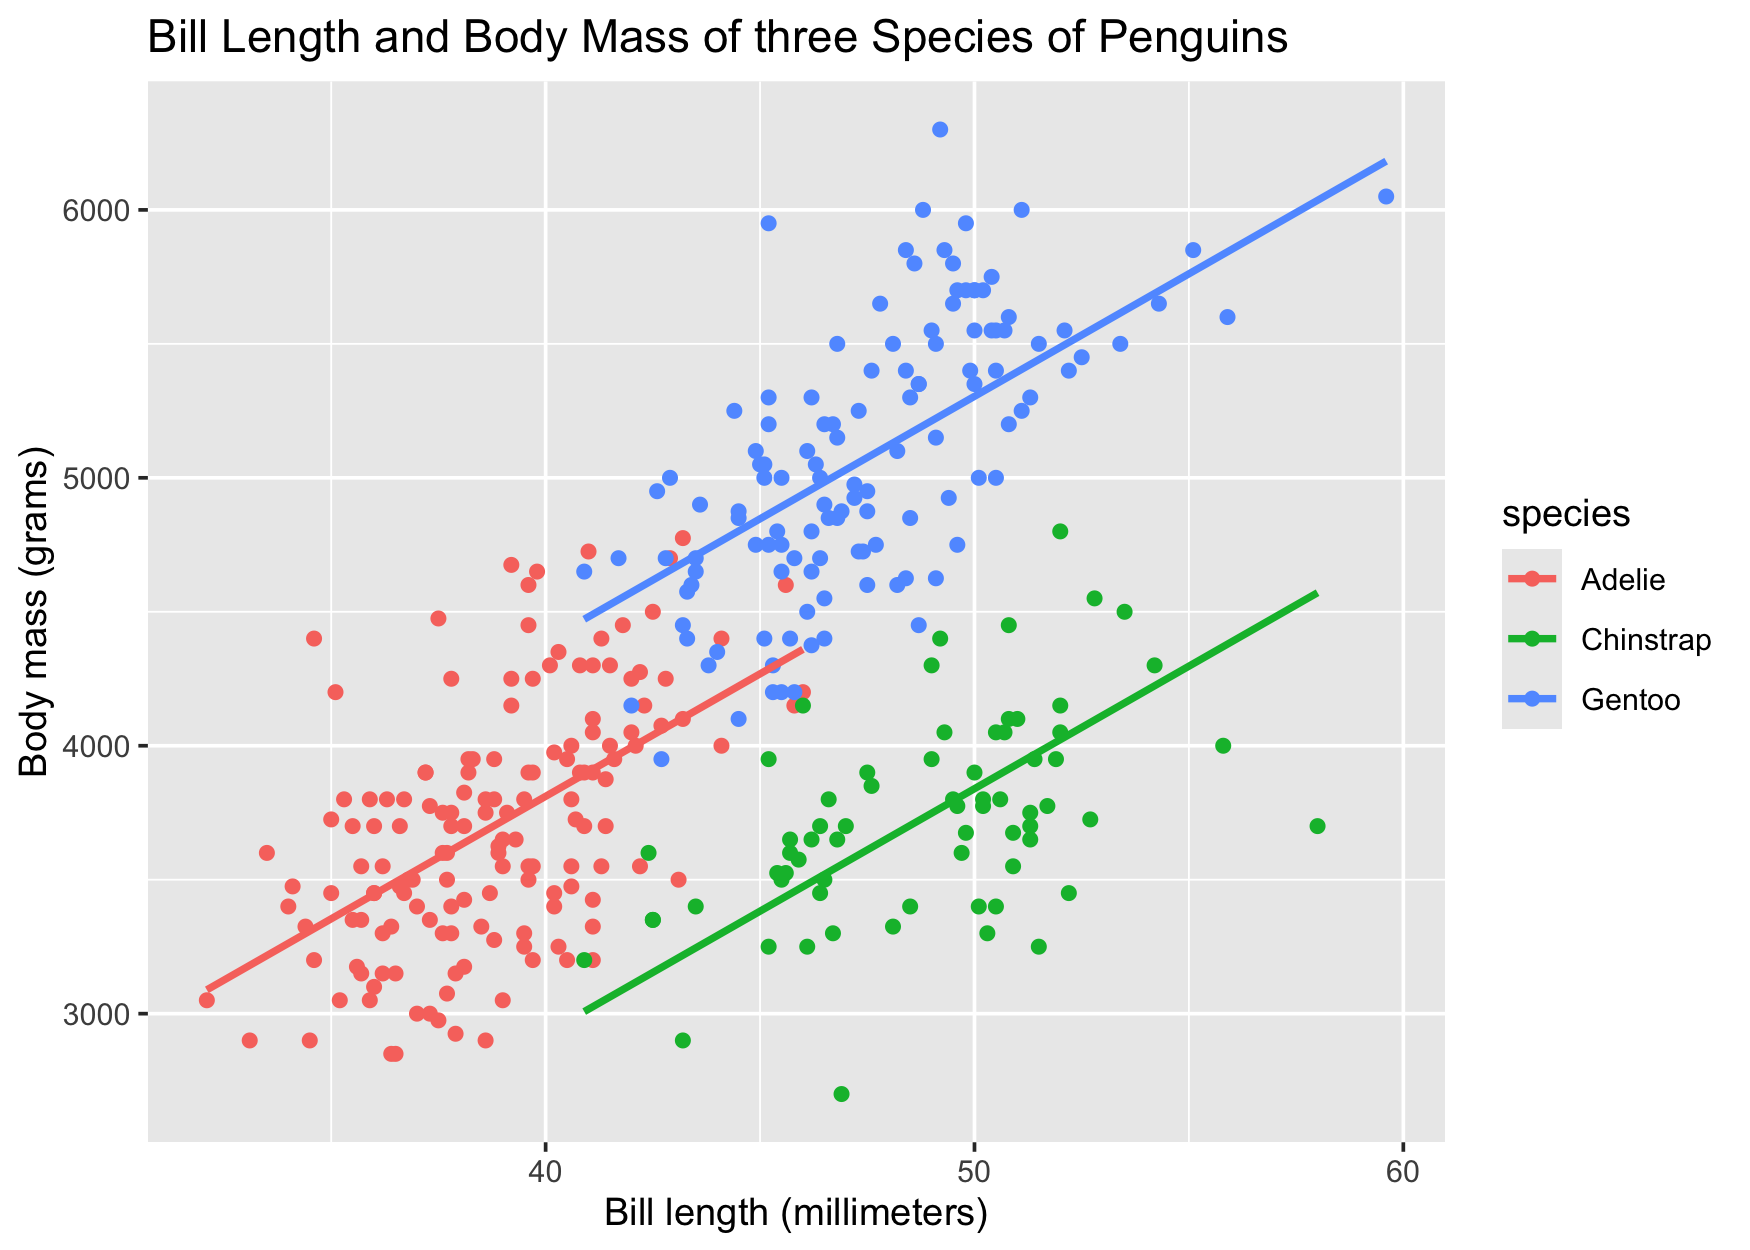

In [16]:
ggplot(data = pen, aes(y = body_mass_g, x = bill_length_mm, color=species)) + 
  geom_point() + 
  geom_parallel_slopes(se = FALSE) +
  labs(x = "Bill length (millimeters)", 
       y = "Body mass (grams)", 
       title = "Bill Length and Body Mass of three Species of Penguins") 

Let’s fit the parallel slopes model

In [17]:
# Fit regression model:

mod = linear_reg() |> set_engine('lm')

pen_parallel = mod |> fit(body_mass_g ~ bill_length_mm + species, data = pen)

# Get regression table:
tidy(pen_parallel)

term,estimate,std.error,statistic,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),153.73969,268.901233,0.5717329,5.678829e-01
bill_length_mm,91.43582,6.887119,13.2763517,1.158990e-32
speciesChinstrap,-885.81208,88.250154,-10.0375131,6.373927e-21
speciesGentoo,578.62916,75.362341,7.6779617,1.756354e-13


Let us once again inspect the conditions necessary for inference with
regression.

1.  Linearity of relationship between variables
2.  Independence of the residuals
3.  Normality of the residuals
4.  Equality of variance of the residuals

## Question 7

**Check for Linearity of relationship between variables **

Would you say that the relationship between `bill_length_mm` and
`body_mass_g` appears to be linear for each species?

**Answer:**

Yes, the relationship looks roughly linear and positive within each species. I added separate fitted lines to check this, because the supplied parallel-slopes plot forces the lines to have the same slope. The Chinstrap line is flatter than the other two, so the common-slope assumption is only an approximation.

`geom_smooth()` using formula = 'y ~ x'


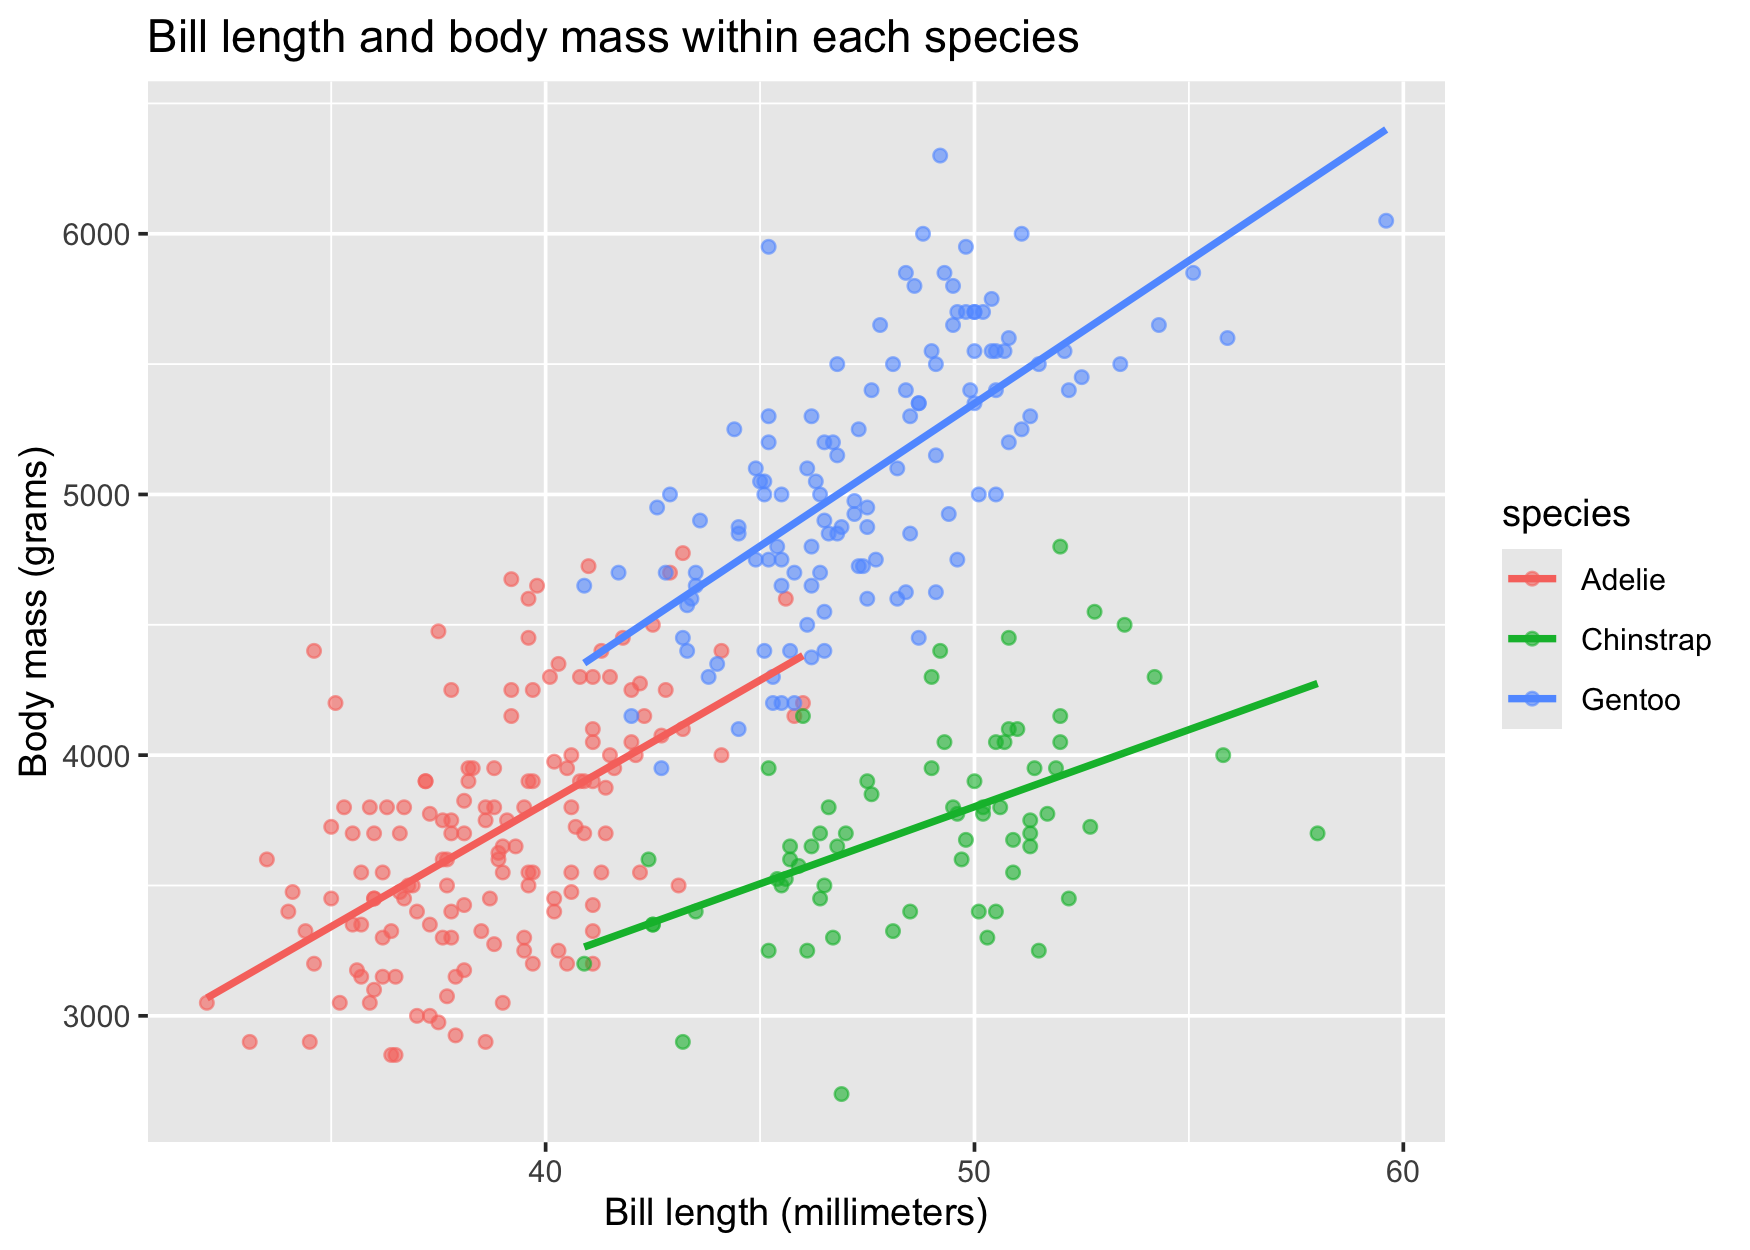

In [18]:
# Fit a separate line for each species to check the pattern within groups.
ggplot(pen, aes(x = bill_length_mm, y = body_mass_g, color = species)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", se = FALSE) +
  labs(title = "Bill length and body mass within each species",
       x = "Bill length (millimeters)", y = "Body mass (grams)")

**Check for Independence of the residuals **

This is the same as the first model that we looked it. The observations
in our data must be independent of one another. In this data, we can not
be sure this is case, for example, some of the penguins included may be
related (siblings, parents). We are not given enough information to
verify this condition has been met.

## Question 8

Check Normality of the residuals (and they should be centered at 0.)

**8a) **

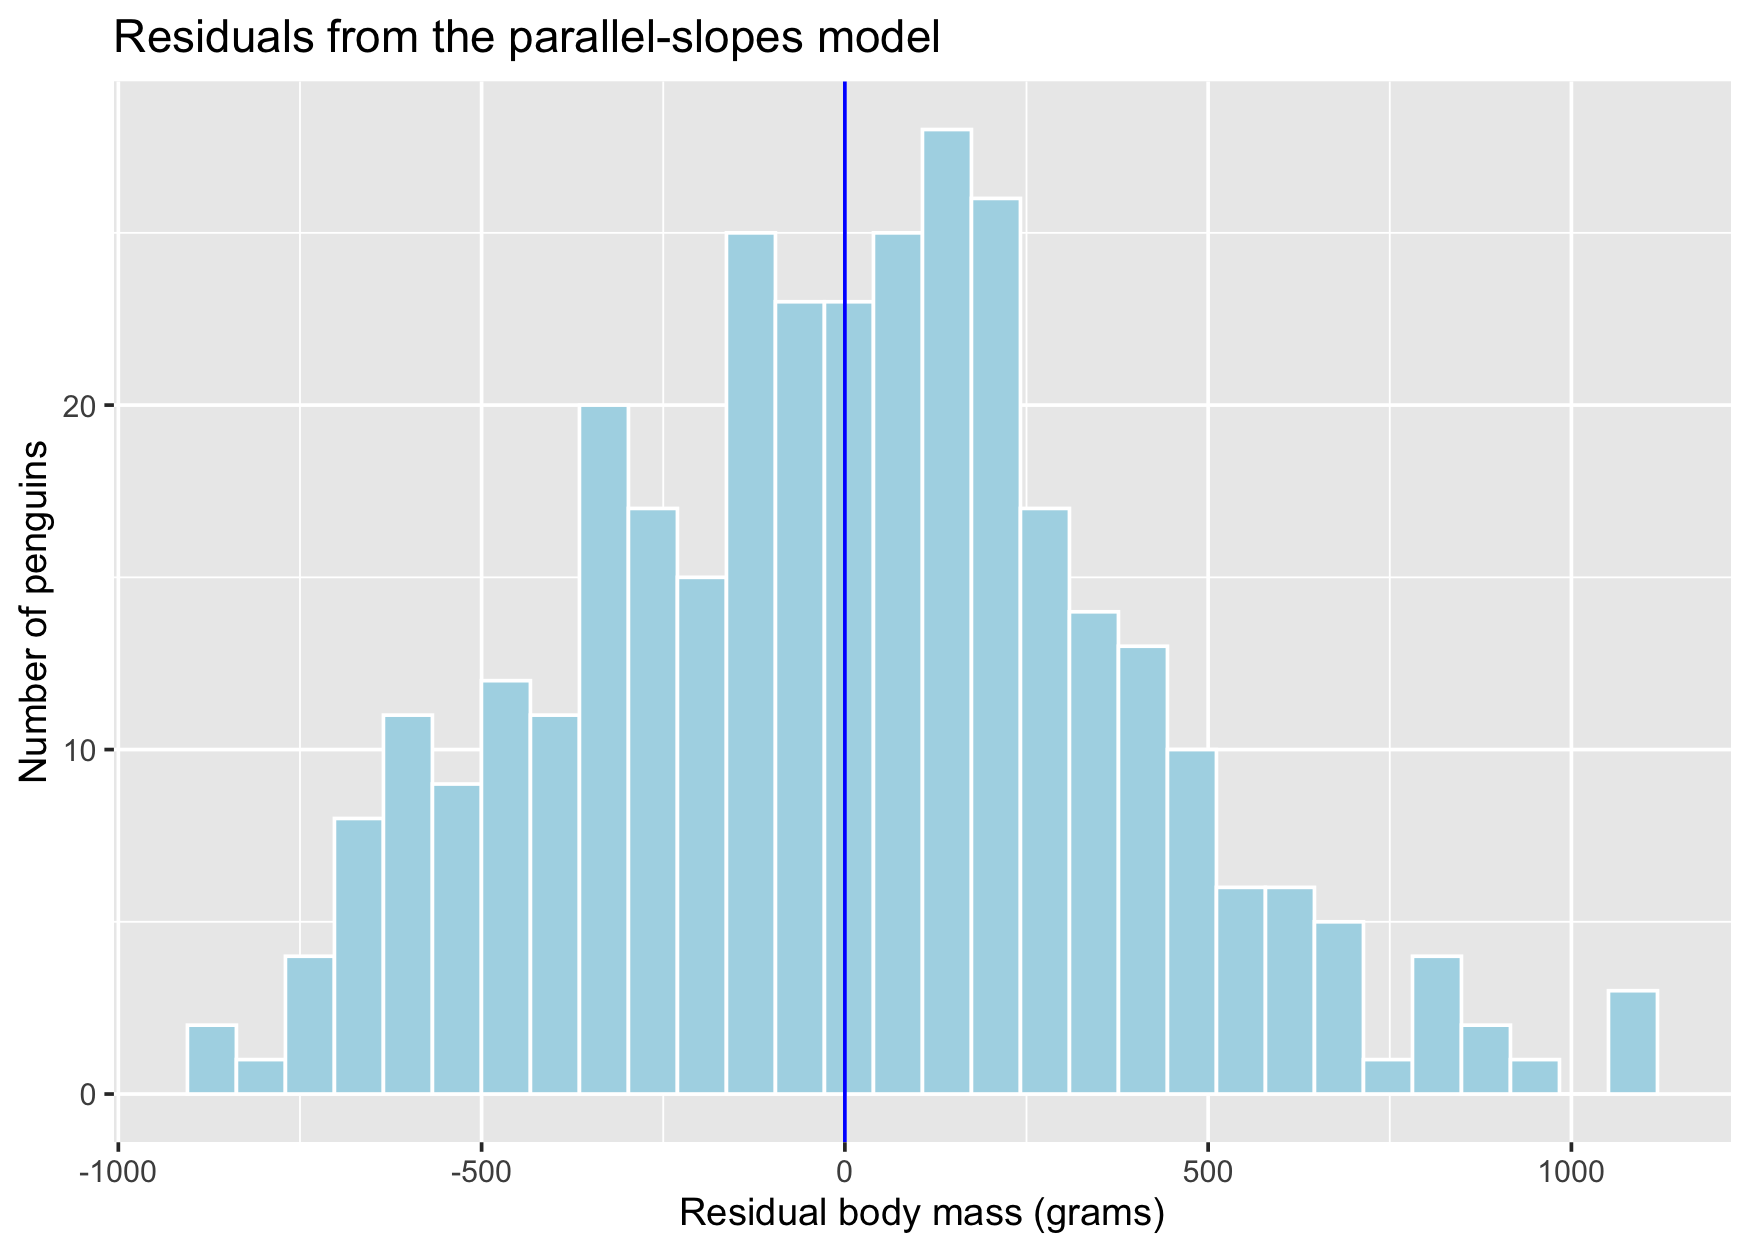

In [19]:
parallel_points = augment(pen_parallel, new_data = pen)

ggplot(parallel_points, aes(x = .resid)) +
  geom_histogram(bins = 30, fill = "lightblue", color = "white") +
  geom_vline(xintercept = 0, color = "blue") +
  labs(title = "Residuals from the parallel-slopes model",
       x = "Residual body mass (grams)", y = "Number of penguins")

**8b)** Does this model meet the Normality of Residuals condition?

**Answer:**

The residuals look approximately normal. The histogram is centered near zero and has a roughly bell-shaped pattern, although it is not perfectly symmetric. Most points in the Q-Q plot follow the line, with some departures in the tails.

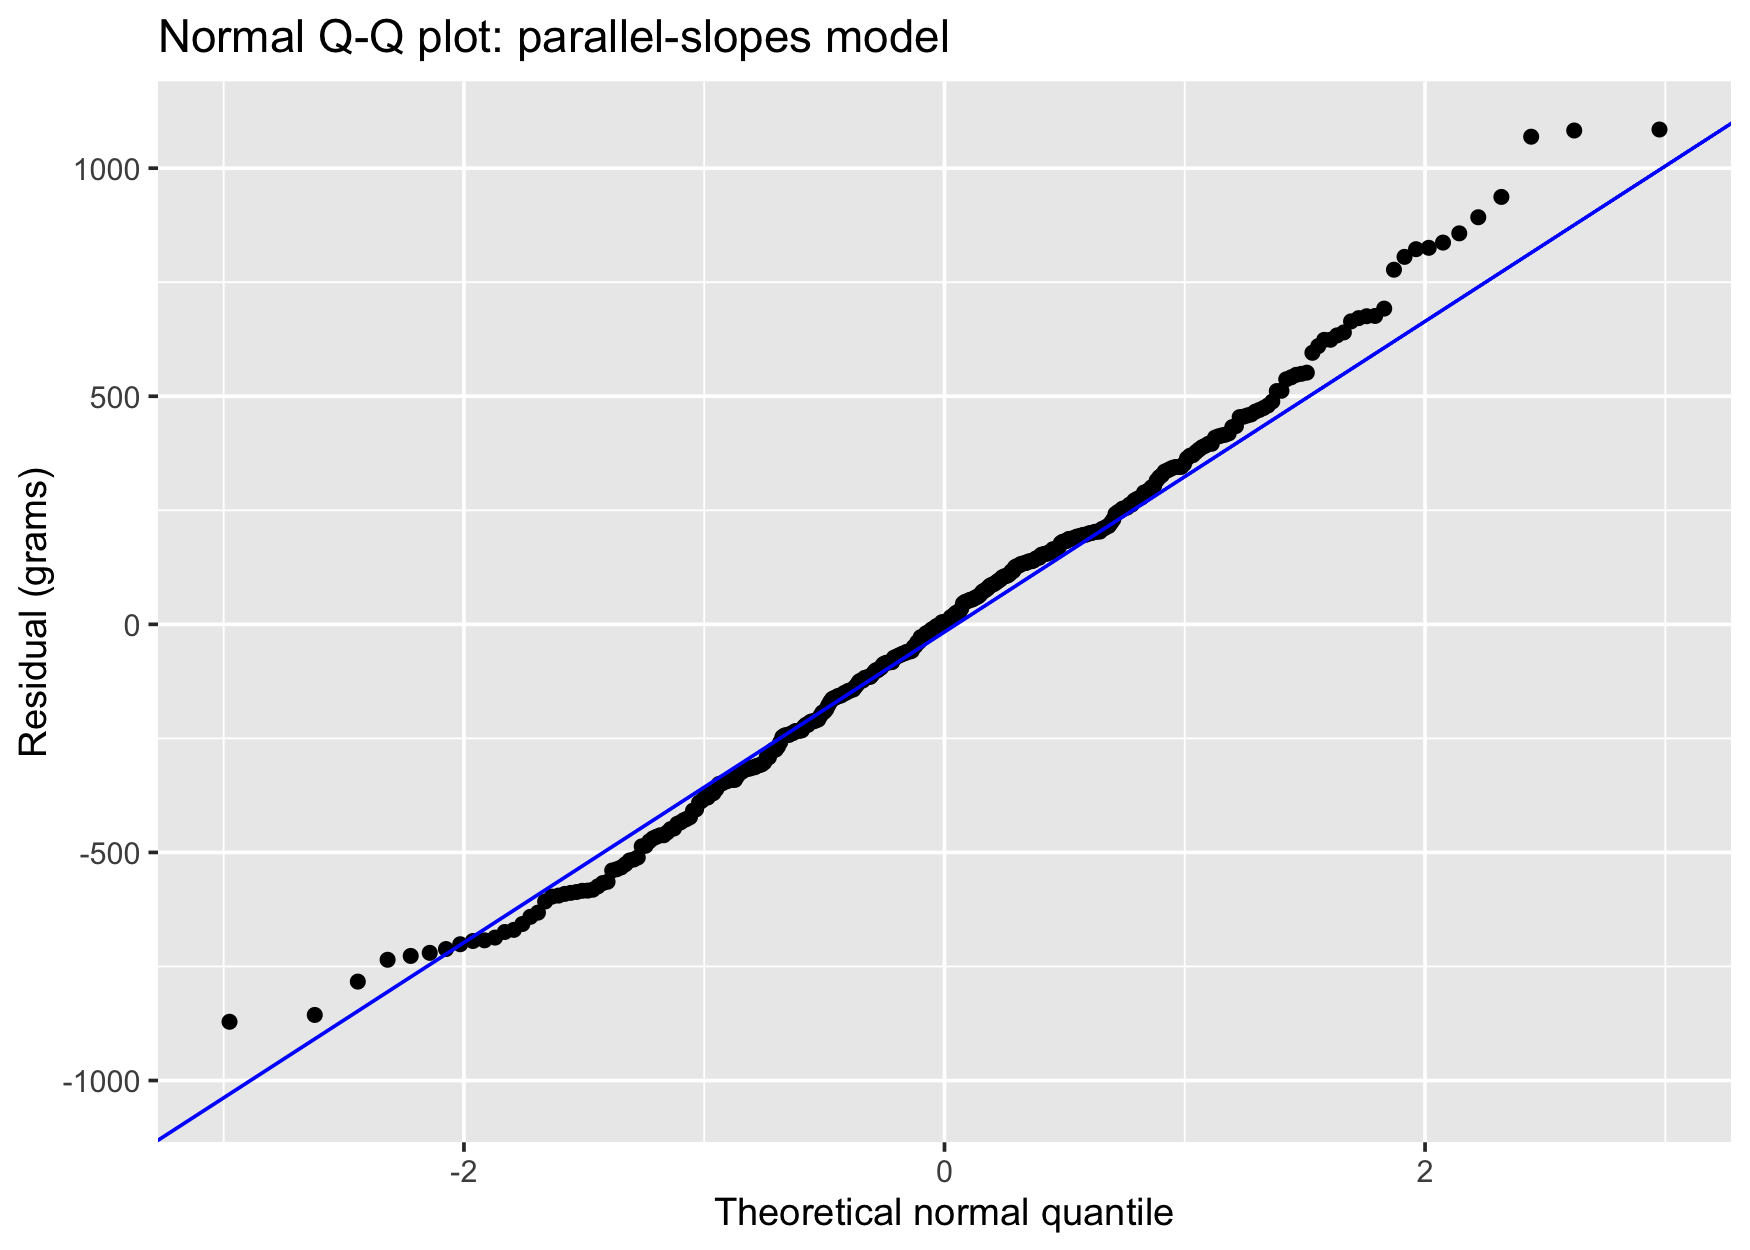

In [20]:
ggplot(parallel_points, aes(sample = .resid)) +
  stat_qq() +
  stat_qq_line(color = "blue") +
  labs(title = "Normal Q-Q plot: parallel-slopes model",
       x = "Theoretical normal quantile", y = "Residual (grams)")

## Question 9

Check for Equality of variance of the residuals

To check this condition we can create a scatterplot that has our
explanatory variable, `flipper_length_mm`, on the x-axis and our
residuals on the y-axis.

**9a)**

**My note:** Part 2 uses bill length and species as predictors, although this question names flipper length. I include that requested plot and also check residuals against the fitted values from the actual parallel-slopes model.

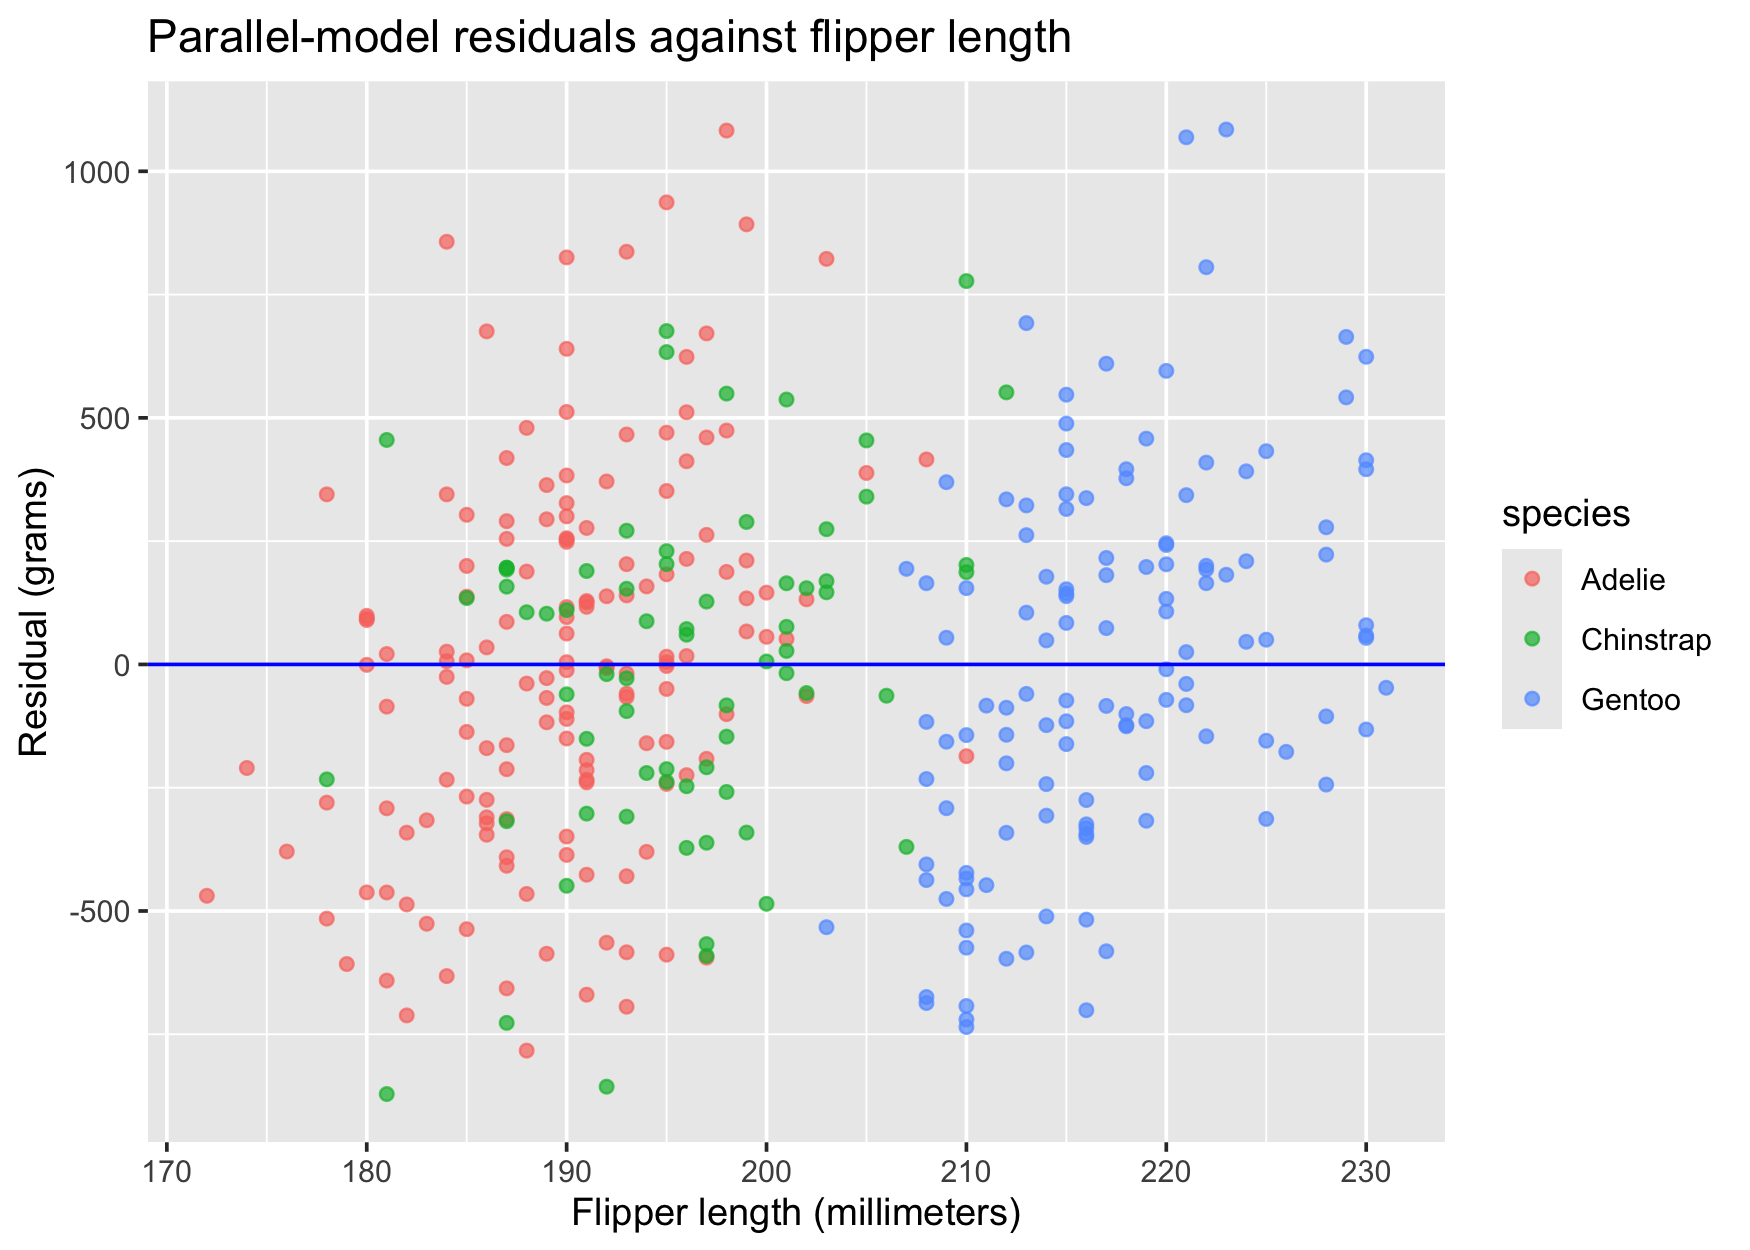

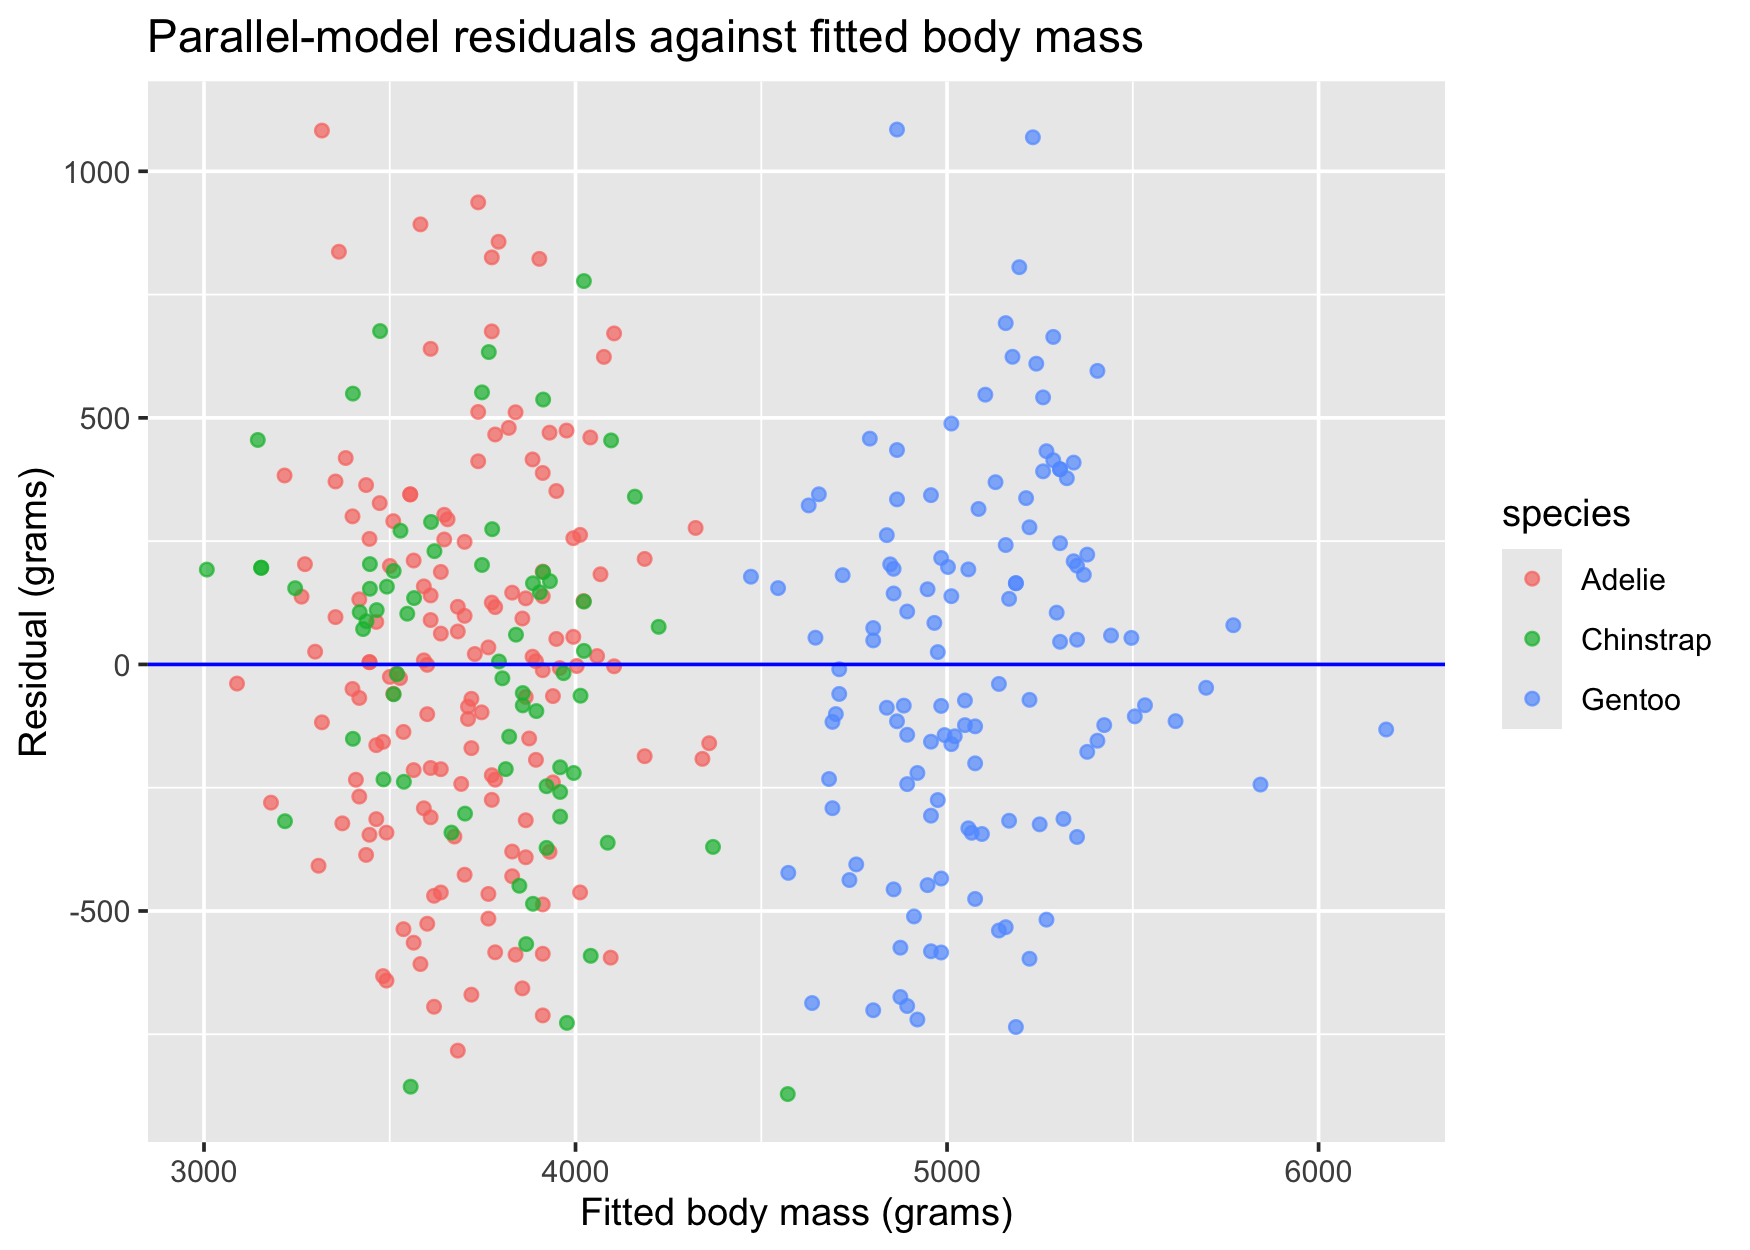

In [21]:
# The first plot follows the variable named in Question 9.
ggplot(parallel_points, aes(x = flipper_length_mm, y = .resid,
                          color = species)) +
  geom_point(alpha = 0.7) +
  geom_hline(yintercept = 0, color = "blue") +
  labs(title = "Parallel-model residuals against flipper length",
       x = "Flipper length (millimeters)", y = "Residual (grams)")

# Fitted values reflect both actual predictors: bill length and species.
ggplot(parallel_points, aes(x = .pred, y = .resid, color = species)) +
  geom_point(alpha = 0.7) +
  geom_hline(yintercept = 0, color = "blue") +
  labs(title = "Parallel-model residuals against fitted body mass",
       x = "Fitted body mass (grams)", y = "Residual (grams)")

**9b) **Does this meet the equality of variance of the residuals
condition?

**Answer:**

I would say the spread is approximately constant. The residuals against fitted values do not show a strong funnel shape. Their standard deviations are about 383 grams for Adelie, 347 for Chinstrap, and 379 for Gentoo, so the group spreads are fairly similar. There are still some large residuals and group patterns, so I would not say that all model conditions are fully verified.

In [22]:
parallel_points |>
  group_by(species) |>
  summarize(n = n(), mean_residual = mean(.resid),
            residual_sd = sd(.resid))

species,n,mean_residual,residual_sd
<fct>,<int>,<dbl>,<dbl>
Adelie,151,1.982320e-12,383.4071
Chinstrap,68,2.557536e-12,346.9718
Gentoo,123,2.790064e-12,378.7108


## Question 10

Run the code below to find the confidence intervals for our model's coefficients.

In [23]:
set.seed(43)

boots = bootstraps(pen, times = 1000, apparent = TRUE)

mod = linear_reg() |> set_engine('lm')

boot_models  = boots |> 
  mutate(model = map(splits, ~mod |> fit(body_mass_g ~ bill_length_mm + species, data = as_tibble(.x))),
         coef_info = map(model, tidy))

boot_coefs = boot_models |> 
  unnest(coef_info)

percentile_intervals = int_pctl(boot_models, coef_info)

percentile_intervals

term,.lower,.estimate,.upper,.alpha,.method
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
(Intercept),-336.73024,148.27461,624.9216,0.05,percentile
bill_length_mm,79.50537,91.56573,104.0297,0.05,percentile
speciesChinstrap,-1033.13626,-886.36048,-750.5226,0.05,percentile
speciesGentoo,445.53475,579.40554,727.0047,0.05,percentile


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


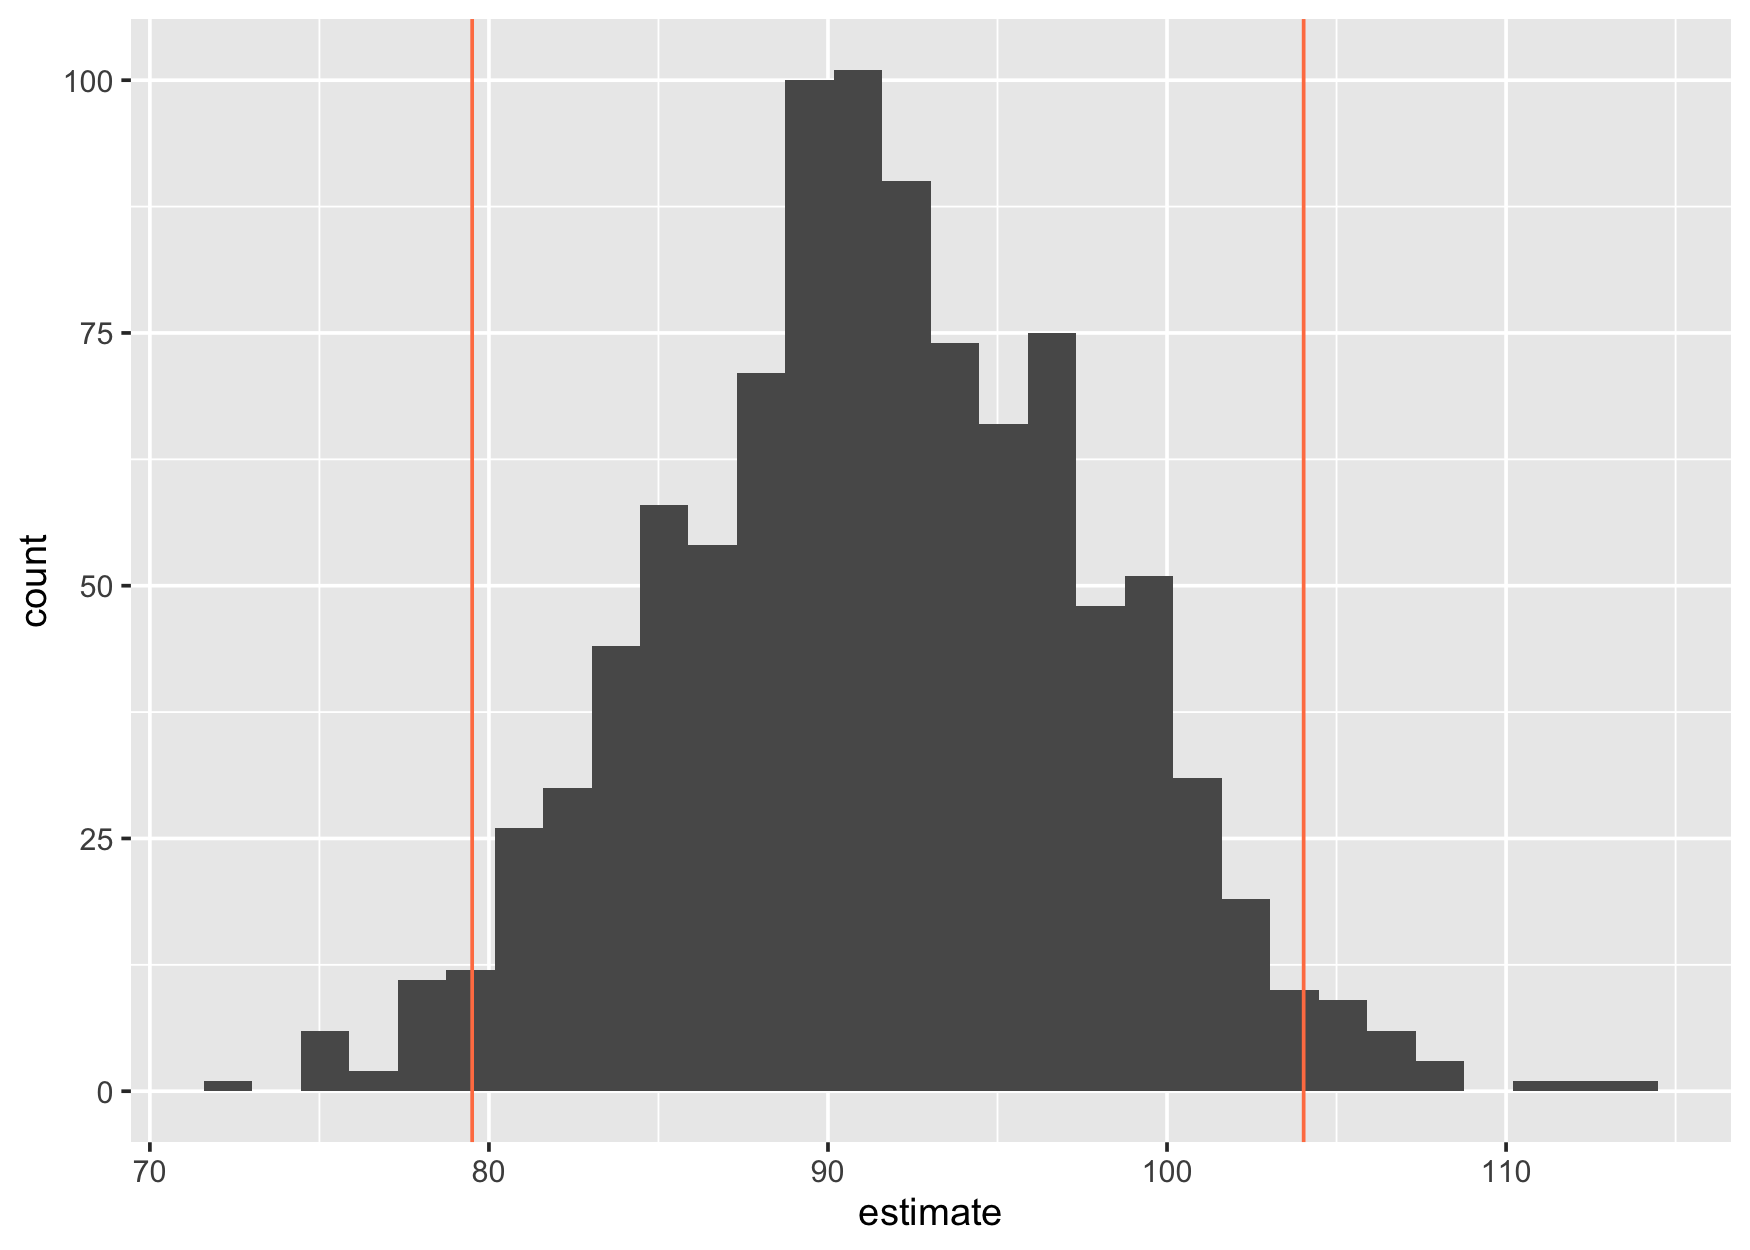

In [24]:
boot_coefs |> 
    filter(term == 'bill_length_mm') |>
ggplot(aes(x = estimate)) +
    geom_histogram() +
    geom_vline(xintercept = percentile_intervals |> filter(term == 'bill_length_mm') |> pull(.lower), color = 'coral') +
    geom_vline(xintercept = percentile_intervals |> filter(term == 'bill_length_mm') |> pull(.upper), color = 'coral')

What can we conclude about the relationship between bill length and body
mass?

**Answer:**

After accounting for species, longer bills are associated with greater mean body mass in this model. The estimated common slope is 91.44 grams per millimeter, and its 95% bootstrap percentile interval is about 79.51 to 104.03 grams per millimeter. Since the whole interval is above zero, it supports a positive association between bill length and mean body mass when comparing penguins of the same species. This is not an interval for individual penguin masses or proof of causation.

These results depend on the common-slope model and independent observations. We cannot verify independence from the information provided, and bootstrapping rows does not fix dependence or an unrepresentative sample.

In [25]:
tidy(pen_parallel) |>
  filter(term == "bill_length_mm")

percentile_intervals |>
  filter(term == "bill_length_mm")

term,estimate,std.error,statistic,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
bill_length_mm,91.43582,6.887119,13.27635,1.15899e-32


term,.lower,.estimate,.upper,.alpha,.method
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
bill_length_mm,79.50537,91.56573,104.0297,0.05,percentile
